<a href="https://colab.research.google.com/github/bognag/li-metal-fluoride-screening/blob/main/lithium_fluoride_screening.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 리튬금속 음극 보호용 불화물계 소재 스크리닝
인공지능재료설계 · 강보경 (20223153)

**목적:** Materials Project의 Li 함유 불화물에서 리튬금속 음극 보호층 후보를 단계별 필터로 찾는다.

**단계:** ① 열역학 안정성(Ehull) → ② 독성·고가 원소 제외 → ③ 전자 절연(밴드갭) → ④ Li 금속과의 반응성

**실행:** 위에서부터 차례로 실행하거나 `런타임 > 모두 실행`. 2번 셀에서 Materials Project API 키를 입력한다.

In [ ]:
!pip install -q pymatgen mp-api

E8ozhhaYjofoLWK7YrCMprkEuHbXtEb3
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-colab 1.0.0 requires requests==2.32.4, but you have requests 2.34.2 which is incompatible.


In [ ]:
from getpass import getpass
MP_API_KEY = getpass("Materials Project API 키를 붙여넣으세요: ")

Materials Project API 키를 붙여넣으세요: ··········


## 1. 필터 기준값

In [ ]:
EHULL_MAX = 0.05      # eV/atom, 열역학 안정성 기준
MIN_BAND_GAP = 4.0    # eV, 전자 절연 기준
RXN_MIN = -0.1        # eV/atom, Li 금속과의 반응 에너지 하한
# 독성·고가·희소 원소 (스크리닝에서 제외)
EXCLUDE = {"Be","Cd","Hg","Pb","Tl","As","Se","Te","Sc","Y","La","Ce","Pr","Nd","Sm","Eu","Gd",
           "Tb","Dy","Ho","Er","Tm","Yb","Lu","Ac","Th","U","Pu","Ir","Rh","Pd","Pt","Au","Ag",
           "Re","Os","Ru","Ge","Ga","In","Cs"}

## 2. 데이터베이스에서 후보 불러오기 (Li과 F를 모두 포함하는 물질)

In [ ]:
from mp_api.client import MPRester
import pandas as pd

with MPRester(MP_API_KEY) as mpr:
    docs = mpr.materials.summary.search(
        elements=["Li", "F"],
        fields=["material_id", "formula_pretty", "chemsys", "energy_above_hull", "band_gap"],
    )

df0 = pd.DataFrame([{
    "material_id": str(d.material_id),
    "formula": d.formula_pretty,
    "chemsys": d.chemsys,
    "ehull": d.energy_above_hull,
    "band_gap": d.band_gap,
} for d in docs])
print("전체 Li 함유 불화물:", len(df0))

Output()

✓ Retrieved 2,582 SummaryDoc documents in 1.9s

전체 Li 함유 불화물: 2582


## 3. 단계별 필터 ①~③ (계산이 싼 필터를 먼저 적용)

In [ ]:
stages = {"전체 Li 함유 불화물": len(df0)}

df1 = df0[df0["ehull"] <= EHULL_MAX]
stages["① 안정성 (Ehull)"] = len(df1)

df2 = df1[~df1["chemsys"].apply(lambda s: bool(set(s.split("-")) & EXCLUDE))]
stages["② 위험·고가 원소 제외"] = len(df2)

df3 = df2[df2["band_gap"] >= MIN_BAND_GAP]
stages["③ 전자 절연 (밴드갭)"] = len(df3)

for k, v in stages.items():
    print(f"{k}: {v}")

전체 Li 함유 불화물: 2582
① 안정성 (Ehull): 851
② 위험·고가 원소 제외: 691
③ 전자 절연 (밴드갭): 95


## 4. 필터 ④ Li 금속과의 반응성 (pymatgen InterfacialReactivity)

In [ ]:
from pymatgen.core import Composition
from pymatgen.analysis.phase_diagram import PhaseDiagram
from pymatgen.analysis.interface_reactions import InterfacialReactivity
from tqdm.auto import tqdm

pd_cache = {}

def min_rxn_energy(formula, chemsys, mpr):
    elements = sorted(set(chemsys.split("-")) | {"Li"})
    key = "-".join(elements)
    if key not in pd_cache:
        pd_cache[key] = PhaseDiagram(mpr.get_entries_in_chemsys(elements))
    ir = InterfacialReactivity(Composition("Li"), Composition(formula), pd_cache[key],
                               norm=True, use_hull_energy=False)
    kinks = ir.get_kinks()
    return min(k[2] for k in kinks)   # 가장 큰 반응 에너지 (eV/atom, 음수일수록 반응 큼)

results = []
with MPRester(MP_API_KEY) as mpr:
    for _, r in tqdm(df3.iterrows(), total=len(df3)):
        try:
            results.append(min_rxn_energy(r["formula"], r["chemsys"], mpr))
        except Exception as e:
            results.append(None)

df3 = df3.copy()
df3["min_rxn_energy"] = results
df4 = df3[df3["min_rxn_energy"] >= RXN_MIN].sort_values("min_rxn_energy", ascending=False)
stages["④ Li 반응성"] = len(df4)
print("계산 실패:", df3["min_rxn_energy"].isna().sum())
print("최종 후보:", len(df4))
df4.head(10)

  0%|          | 0/95 [00:00<?, ?it/s]

Output()

Output()

Output()

Output()

Output()

... (58 outputs left out)

Output()

Output()

계산 실패: 0
최종 후보: 3


,material_id,formula,chemsys,ehull,band_gap,min_rxn_energy
83,mp-1185301,LiF,F-Li,0.024406,8.7581,0.000000
157,mp-1138,LiF,F-Li,0.000000,8.7161,0.000000
788,mp-10250,BaLiF3,Ba-F-Li,0.021903,6.5716,-0.049371


## 5. 결과 시각화

/tmp/ipykernel_700/2798649526.py:10: UserWarning: Glyph 54980 (\N{HANGUL SYLLABLE HU}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_700/2798649526.py:10: UserWarning: Glyph 48372 (\N{HANGUL SYLLABLE BO}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_700/2798649526.py:10: UserWarning: Glyph 49688 (\N{HANGUL SYLLABLE SU}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_700/2798649526.py:10: UserWarning: Glyph 48152 (\N{HANGUL SYLLABLE BAN}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_700/2798649526.py:10: UserWarning: Glyph 51025 (\N{HANGUL SYLLABLE EUNG}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_700/2798649526.py:10: UserWarning: Glyph 49457 (\N{HANGUL SYLLABLE SEONG}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_700/2798649526.py:10: UserWarning: Glyph 51204 (\N{HANGUL SYLLABLE JEON}) missing from font(s) DejaVu Sans.
  plt.tight_layout(

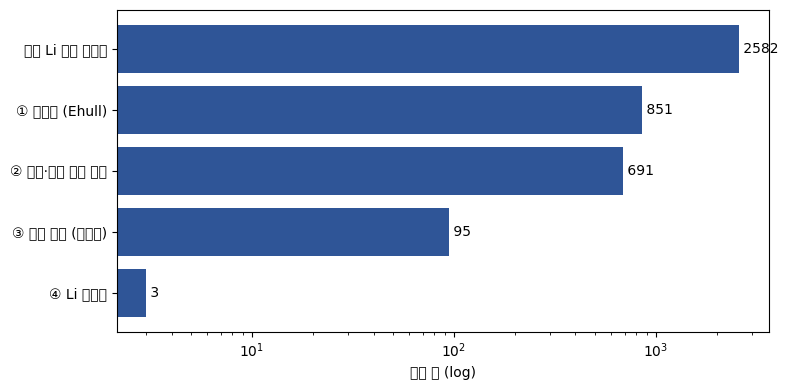

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 4))
names, vals = list(stages.keys())[::-1], list(stages.values())[::-1]
plt.barh(names, vals, color="#2f5597")
plt.xscale("log")
for i, v in enumerate(vals):
    plt.text(v, i, f" {v}", va="center")
plt.xlabel("후보 수 (log)")
plt.tight_layout()
plt.savefig("funnel.png", dpi=200)
plt.show()

/tmp/ipykernel_700/2997023399.py:7: UserWarning: Glyph 48152 (\N{HANGUL SYLLABLE BAN}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_700/2997023399.py:7: UserWarning: Glyph 51025 (\N{HANGUL SYLLABLE EUNG}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_700/2997023399.py:7: UserWarning: Glyph 50640 (\N{HANGUL SYLLABLE E}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_700/2997023399.py:7: UserWarning: Glyph 45320 (\N{HANGUL SYLLABLE NEO}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_700/2997023399.py:7: UserWarning: Glyph 51648 (\N{HANGUL SYLLABLE JI}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_700/2997023399.py:7: UserWarning: Glyph 44592 (\N{HANGUL SYLLABLE GI}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_700/2997023399.py:7: UserWarning: Glyph 51456 (\N{HANGUL SYLLABLE JUN}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipyk

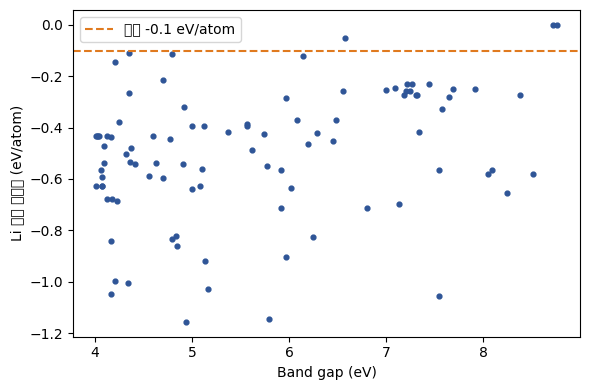

In [ ]:
plt.figure(figsize=(6, 4))
plt.scatter(df3["band_gap"], df3["min_rxn_energy"], s=12, color="#2f5597")
plt.axhline(RXN_MIN, color="#e07a1f", linestyle="--", label=f"기준 {RXN_MIN} eV/atom")
plt.xlabel("Band gap (eV)")
plt.ylabel("Li 반응 에너지 (eV/atom)")
plt.legend()
plt.tight_layout()
plt.savefig("reactivity.png", dpi=200)
plt.show()

## 6. 결과 저장과 확인

In [ ]:
df4.to_csv("candidates.csv", index=False)
print(df4[["material_id", "formula", "ehull", "band_gap", "min_rxn_energy"]].head(10).to_string(index=False))
print()
print("대조군 LiF:")
print(df0[df0["formula"] == "LiF"][["material_id", "ehull", "band_gap"]].to_string(index=False))

material_id formula    ehull  band_gap  min_rxn_energy
 mp-1185301     LiF 0.024406    8.7581        0.000000
    mp-1138     LiF 0.000000    8.7161        0.000000
   mp-10250  BaLiF3 0.021903    6.5716       -0.049371

대조군 LiF:
material_id    ehull  band_gap
 mp-1009009 0.287542    7.5593
 mp-1185301 0.024406    8.7581
    mp-1138 0.000000    8.7161


## 해석 메모
- 단계별 후보 수와 통과율을 정리한다.
- 반응 에너지가 가장 큰 후보와 가장 작은 후보를 비교한다.
- 한계: 결정질·0 K 계산 기반이며 Li+ 전도도와 기계적 물성은 다루지 않았다.

## GitHub에 올리기
Colab 메뉴 `파일 > GitHub에 사본 저장`을 선택한다. API 키는 저장되지 않는다(getpass 입력).